# ECG signal quality and preprocessing

In [8]:
from __future__ import annotations

import json
import logging
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import wfdb

from scipy.signal import butter, sosfiltfilt, iirnotch, filtfilt, welch

RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

logging.basicConfig(level=logging.INFO, format="%(levelname)s: %(message)s")
logger = logging.getLogger("ptbxl_preprocessing")

plt.rcParams["figure.figsize"] = (14, 5)

## Step 1: Paths and metadata

In [9]:
from pathlib import Path

CURRENT_DIR = Path.cwd().resolve()
PROJECT_ROOT = next(
    (
        parent
        for parent in (CURRENT_DIR, *CURRENT_DIR.parents)
        if (parent / "data" / "raw" / "ptb-xl" / "ptbxl_database.csv").is_file()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate the project root. Expected "
        "'data/raw/ptb-xl/ptbxl_database.csv' in the current directory "
        f"or one of its parents. Current directory: {CURRENT_DIR}"
    )

DATA_ROOT = PROJECT_ROOT / "data" / "raw" / "ptb-xl"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
OUTPUT_DIR = PROJECT_ROOT / "results" / "preprocessing"

DATABASE_PATH = DATA_ROOT / "ptbxl_database.csv"
LABEL_PATH = PROCESSED_DIR / "ptbxl_labels.csv"

if not DATABASE_PATH.is_file():
    raise FileNotFoundError(f"PTB-XL metadata not found: {DATABASE_PATH}")
if not LABEL_PATH.is_file():
    raise FileNotFoundError(
        f"Label file not found: {LABEL_PATH}. Run Notebook 02 first."
    )

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

metadata = pd.read_csv(DATABASE_PATH, index_col="ecg_id")
labels = pd.read_csv(LABEL_PATH, index_col="ecg_id")

metadata.index = pd.to_numeric(metadata.index, errors="raise").astype("int64")
labels.index = pd.to_numeric(labels.index, errors="raise").astype("int64")
metadata.index.name = labels.index.name = "ecg_id"

if metadata.index.has_duplicates:
    raise ValueError("Duplicate ecg_id values found in PTB-XL metadata.")
if labels.index.has_duplicates:
    raise ValueError("Duplicate ecg_id values found in the label file.")

missing_label_ids = metadata.index.difference(labels.index)
extra_label_ids = labels.index.difference(metadata.index)
if len(missing_label_ids) or len(extra_label_ids):
    raise ValueError(
        "Metadata and label ECG IDs do not match. "
        f"Missing labels: {len(missing_label_ids)}; "
        f"extra label IDs: {len(extra_label_ids)}."
    )

labels = labels.loc[metadata.index]

required_metadata_columns = {"filename_hr", "patient_id"}
required_label_columns = {"mi_label", "dataset_split"}
missing_metadata = required_metadata_columns - set(metadata.columns)
missing_labels = required_label_columns - set(labels.columns)

if missing_metadata:
    raise ValueError(f"Metadata is missing columns: {sorted(missing_metadata)}")
if missing_labels:
    raise ValueError(f"Labels are missing columns: {sorted(missing_labels)}")

labels["mi_label"] = pd.to_numeric(labels["mi_label"], errors="raise").astype("int8")
if not labels["mi_label"].isin([0, 1]).all():
    raise ValueError("mi_label must contain only binary values 0 and 1.")

print("Project root:", PROJECT_ROOT)
print("Dataset root:", DATA_ROOT)
print("Processed labels:", LABEL_PATH)
print("Records:", len(metadata))
print("Labels:", labels.shape)

Project root: C:\Users\sintu\Desktop\Myocardial Infarction
Dataset root: C:\Users\sintu\Desktop\Myocardial Infarction\data\raw\ptb-xl
Processed labels: C:\Users\sintu\Desktop\Myocardial Infarction\data\processed\ptbxl_labels.csv
Records: 21799
Labels: (21799, 12)


## Step 2: ECG loading utility

In [10]:
def load_ecg_record(
    ecg_id: int,
    metadata_frame: pd.DataFrame,
    data_root: Path,
) -> tuple[np.ndarray, dict[str, Any]]:
    """Load and validate one high-resolution PTB-XL ECG record."""
    if ecg_id not in metadata_frame.index:
        raise KeyError(f"Unknown ECG ID: {ecg_id}")

    relative_record_path = metadata_frame.loc[ecg_id, "filename_hr"]
    if pd.isna(relative_record_path) or not str(relative_record_path).strip():
        raise ValueError(f"Missing filename_hr for ECG ID {ecg_id}.")

    record_path = (data_root / str(relative_record_path)).resolve()
    root_resolved = data_root.resolve()

    # Prevent malformed metadata paths from escaping the dataset directory.
    if root_resolved not in record_path.parents:
        raise ValueError(f"Record path is outside the dataset directory: {record_path}")

    header_path = record_path.with_suffix(".hea")
    if not header_path.is_file():
        raise FileNotFoundError(
            f"WFDB header not found for ECG {ecg_id}: {header_path}"
        )

    signal, fields = wfdb.rdsamp(str(record_path))
    signal = np.asarray(signal, dtype=np.float32)

    if signal.ndim != 2 or signal.shape[1] != 12:
        raise ValueError(
            f"ECG {ecg_id}: expected (samples, 12), received {signal.shape}."
        )
    if signal.shape[0] < 2:
        raise ValueError(f"ECG {ecg_id} contains too few samples.")
    if not np.isfinite(signal).all():
        raise ValueError(f"Non-finite values found in ECG {ecg_id}.")

    sampling_rate = float(fields.get("fs", 0))
    if not np.isfinite(sampling_rate) or sampling_rate <= 0:
        raise ValueError(f"Invalid sampling frequency for ECG {ecg_id}.")

    return signal, fields


example_ecg_id = int(metadata.index[0])
signal_raw, fields = load_ecg_record(example_ecg_id, metadata, DATA_ROOT)
fs = float(fields["fs"])
lead_names = list(fields["sig_name"])

if len(lead_names) != 12:
    raise ValueError(f"Expected 12 lead names, received {len(lead_names)}.")

print("ECG ID:", example_ecg_id)
print("Shape:", signal_raw.shape)
print("Sampling rate:", fs, "Hz")
print("Duration:", signal_raw.shape[0] / fs, "seconds")
print("Leads:", lead_names)
print("Units:", fields.get("units", "not provided"))

ECG ID: 1
Shape: (5000, 12)
Sampling rate: 500.0 Hz
Duration: 10.0 seconds
Leads: ['I', 'II', 'III', 'AVR', 'AVL', 'AVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']
Units: ['mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV']


## Step 3: Per-lead signal summary

In [11]:
def signal_summary(signal: np.ndarray, names: list[str]) -> pd.DataFrame:
    rows = []
    for i, name in enumerate(names):
        x = signal[:, i]
        rows.append({
            "lead": name,
            "mean_mV": float(x.mean()),
            "std_mV": float(x.std()),
            "min_mV": float(x.min()),
            "max_mV": float(x.max()),
            "peak_to_peak_mV": float(np.ptp(x)),
            "unique_samples": int(np.unique(x).size),
        })
    return pd.DataFrame(rows).set_index("lead")


display(signal_summary(signal_raw, lead_names).round(4))

,mean_mV,std_mV,min_mV,max_mV,peak_to_peak_mV,unique_samples
lead,,,,,,
I,0.0026,0.1115,-0.240,0.690,0.930,532
II,0.0023,0.0860,-0.173,0.508,0.681,429
III,-0.0003,0.0600,-0.365,0.185,0.550,340
AVR,-0.0025,0.0949,-0.597,0.177,0.774,470
AVL,0.0015,0.0785,-0.202,0.513,0.715,409
AVF,0.0010,0.0487,-0.113,0.176,0.289,265
V1,-0.0011,0.1134,-0.736,0.157,0.893,413
V2,0.0088,0.2156,-1.444,0.428,1.872,639
V3,-0.0003,0.1192,-0.625,0.570,1.195,555


## Step 4: Plot all 12 leads

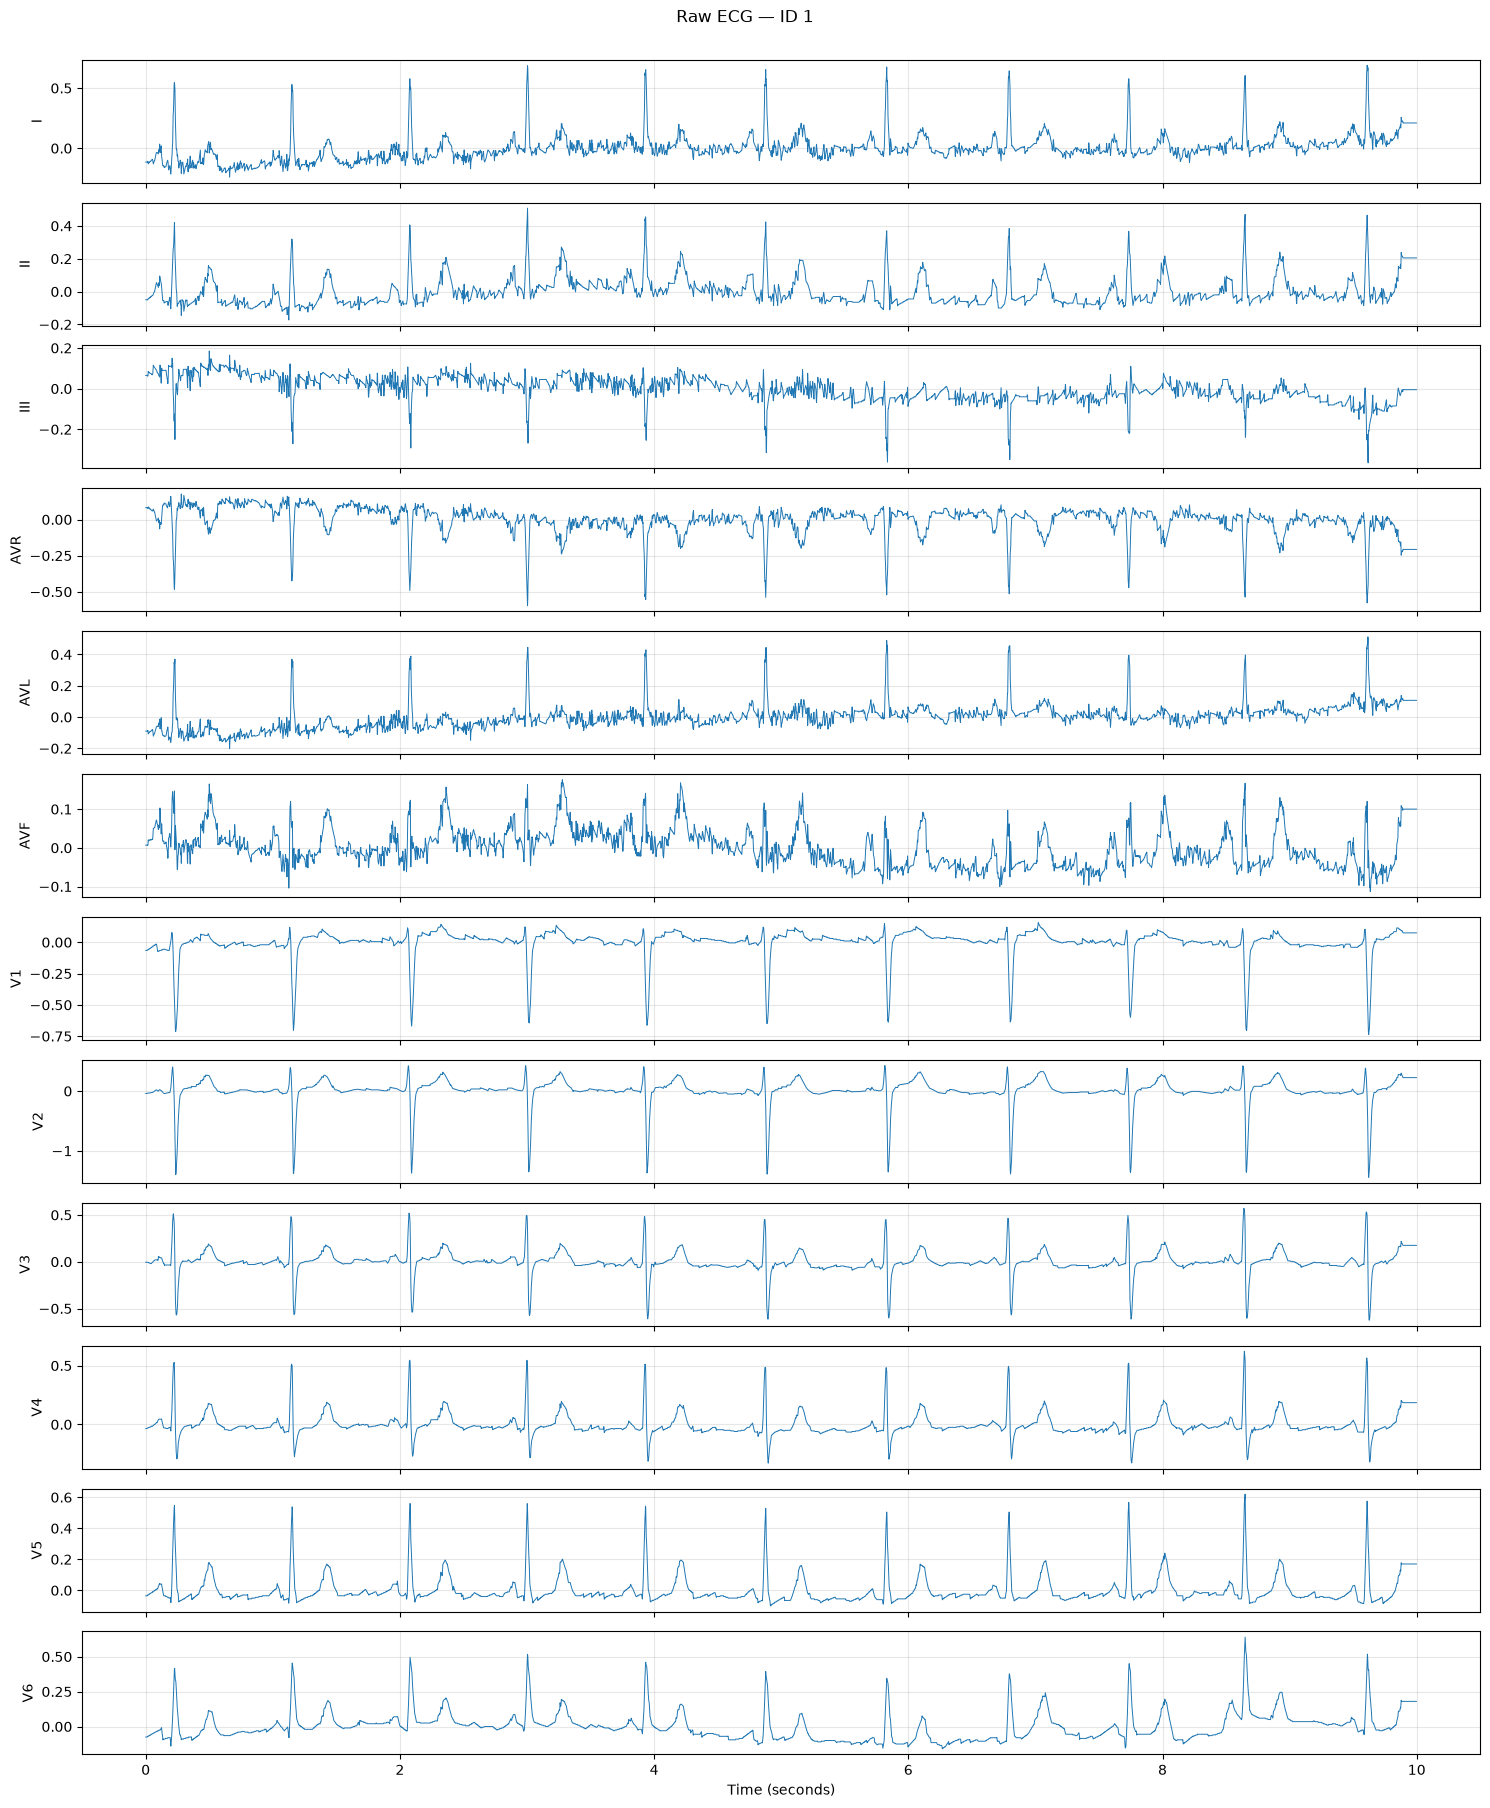

In [12]:
def plot_12_lead_ecg(
    signal: np.ndarray,
    sampling_rate: float,
    names: list[str],
    title: str,
) -> None:
    time = np.arange(signal.shape[0]) / sampling_rate
    fig, axes = plt.subplots(12, 1, figsize=(15, 18), sharex=True)
    for i, ax in enumerate(axes):
        ax.plot(time, signal[:, i], linewidth=0.7)
        ax.set_ylabel(names[i])
        ax.grid(True, alpha=0.3)
    axes[-1].set_xlabel("Time (seconds)")
    fig.suptitle(title, y=1.002)
    plt.tight_layout()
    plt.show()


plot_12_lead_ecg(
    signal_raw, fs, lead_names, f"Raw ECG — ID {example_ecg_id}"
)

## Step 5: Candidate filtering methods

In [13]:
BANDPASS_LOW_HZ = 0.5
BANDPASS_HIGH_HZ = 40.0
FILTER_ORDER = 4

NOTCH_FREQUENCY_HZ = 50.0
NOTCH_QUALITY_FACTOR = 30.0

if not (0 < BANDPASS_LOW_HZ < BANDPASS_HIGH_HZ < fs / 2):
    raise ValueError(
        f"Invalid band-pass cutoffs for sampling rate {fs} Hz. "
        "Require 0 < low < high < Nyquist."
    )


def apply_bandpass(
    signal: np.ndarray,
    sampling_rate: float,
    low_hz: float = BANDPASS_LOW_HZ,
    high_hz: float = BANDPASS_HIGH_HZ,
    order: int = FILTER_ORDER,
) -> np.ndarray:
    """Apply zero-phase Butterworth band-pass filtering along the sample axis."""
    signal = np.asarray(signal, dtype=np.float32)
    if signal.ndim != 2 or not np.isfinite(signal).all():
        raise ValueError("signal must be a finite 2-D ECG array.")
    if sampling_rate <= 0 or order < 1:
        raise ValueError("sampling_rate and filter order must be positive.")
    if not (0 < low_hz < high_hz < sampling_rate / 2):
        raise ValueError("Cutoffs must satisfy 0 < low < high < Nyquist.")

    sos = butter(
        order,
        [low_hz, high_hz],
        btype="bandpass",
        fs=sampling_rate,
        output="sos",
    )
    try:
        filtered = sosfiltfilt(sos, signal, axis=0)
    except ValueError as exc:
        raise ValueError(
            "ECG record is too short for zero-phase filtering with this "
            "filter configuration."
        ) from exc
    return filtered.astype(np.float32)


def apply_notch(
    signal: np.ndarray,
    sampling_rate: float,
    frequency_hz: float = NOTCH_FREQUENCY_HZ,
    quality_factor: float = NOTCH_QUALITY_FACTOR,
) -> np.ndarray:
    """Apply zero-phase IIR notch filtering along the sample axis."""
    signal = np.asarray(signal, dtype=np.float32)
    if signal.ndim != 2 or not np.isfinite(signal).all():
        raise ValueError("signal must be a finite 2-D ECG array.")
    if sampling_rate <= 0 or quality_factor <= 0:
        raise ValueError("sampling_rate and quality_factor must be positive.")
    if not (0 < frequency_hz < sampling_rate / 2):
        raise ValueError("Notch frequency must be below the Nyquist frequency.")

    b, a = iirnotch(frequency_hz, quality_factor, fs=sampling_rate)
    try:
        filtered = filtfilt(b, a, signal, axis=0)
    except ValueError as exc:
        raise ValueError(
            "ECG record is too short for zero-phase notch filtering."
        ) from exc
    return filtered.astype(np.float32)


signal_bandpass = apply_bandpass(signal_raw, fs)

signal_notch = apply_notch(signal_raw, fs)

print("Raw:", signal_raw.shape)
print("Band-pass:", signal_bandpass.shape)
print("Notch-only:", signal_notch.shape)

Raw: (5000, 12)
Band-pass: (5000, 12)
Notch-only: (5000, 12)


## Step 6: Compare raw and filtered waveforms

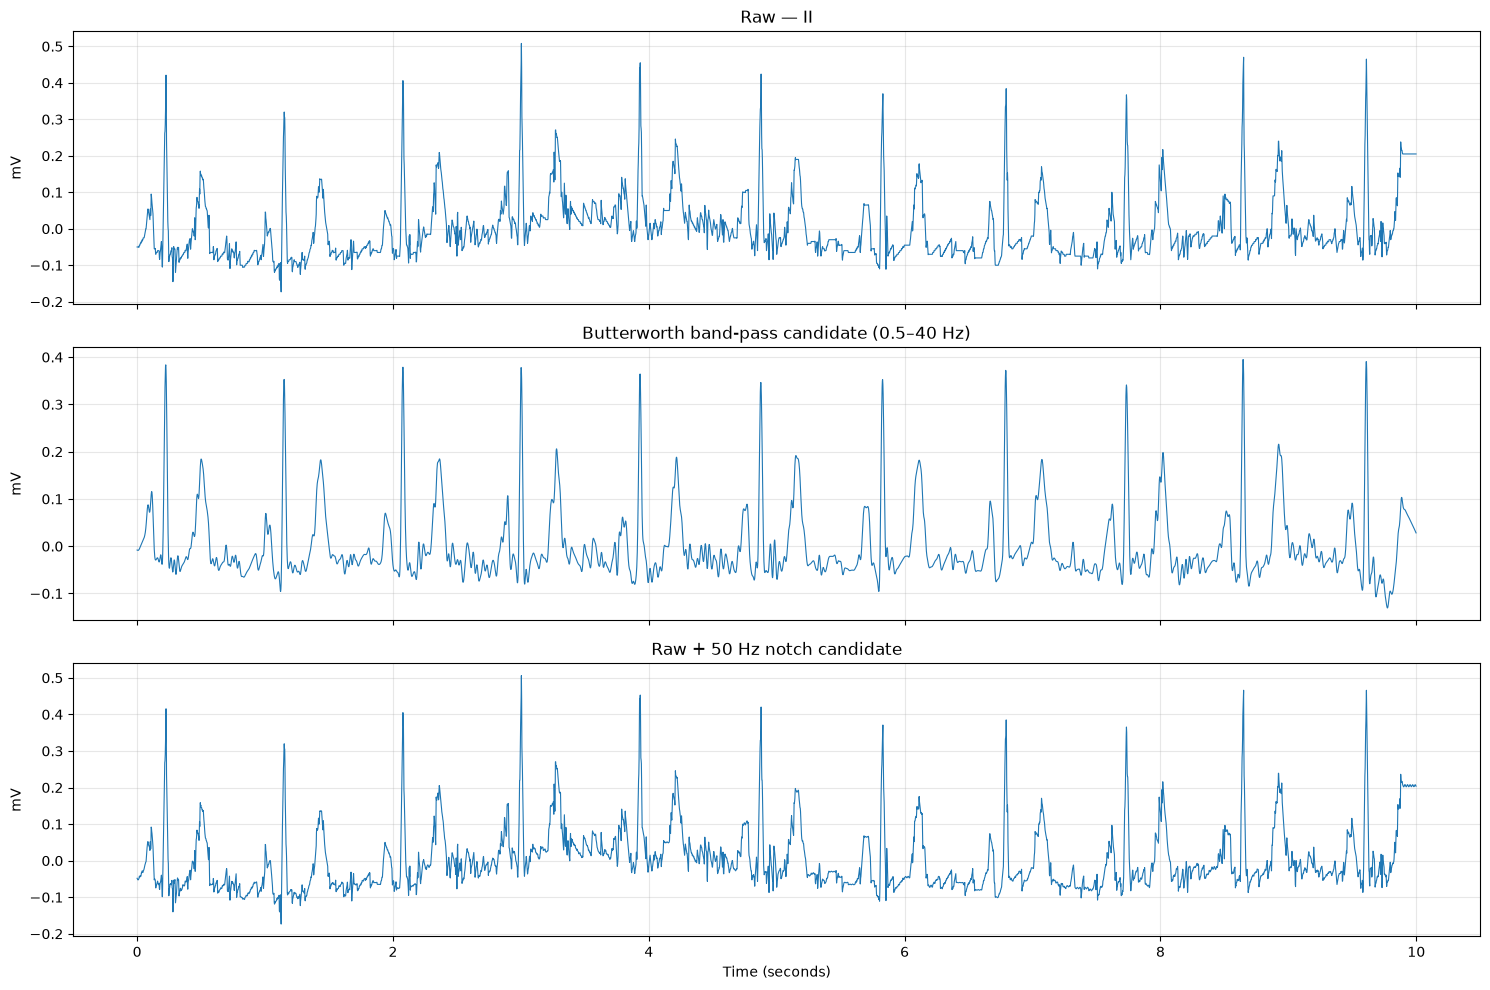

In [14]:
lead_to_inspect = "II"
lead_index = lead_names.index(lead_to_inspect) if lead_to_inspect in lead_names else 1
time = np.arange(signal_raw.shape[0]) / fs

fig, axes = plt.subplots(3, 1, figsize=(15, 10), sharex=True)
axes[0].plot(time, signal_raw[:, lead_index], linewidth=0.8)
axes[0].set_title(f"Raw — {lead_names[lead_index]}")
axes[1].plot(time, signal_bandpass[:, lead_index], linewidth=0.8)
axes[1].set_title("Butterworth band-pass candidate (0.5–40 Hz)")
axes[2].plot(time, signal_notch[:, lead_index], linewidth=0.8)
axes[2].set_title("Raw + 50 Hz notch candidate")
axes[2].set_xlabel("Time (seconds)")
for ax in axes:
    ax.set_ylabel("mV")
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Step 7: Compare power spectral density

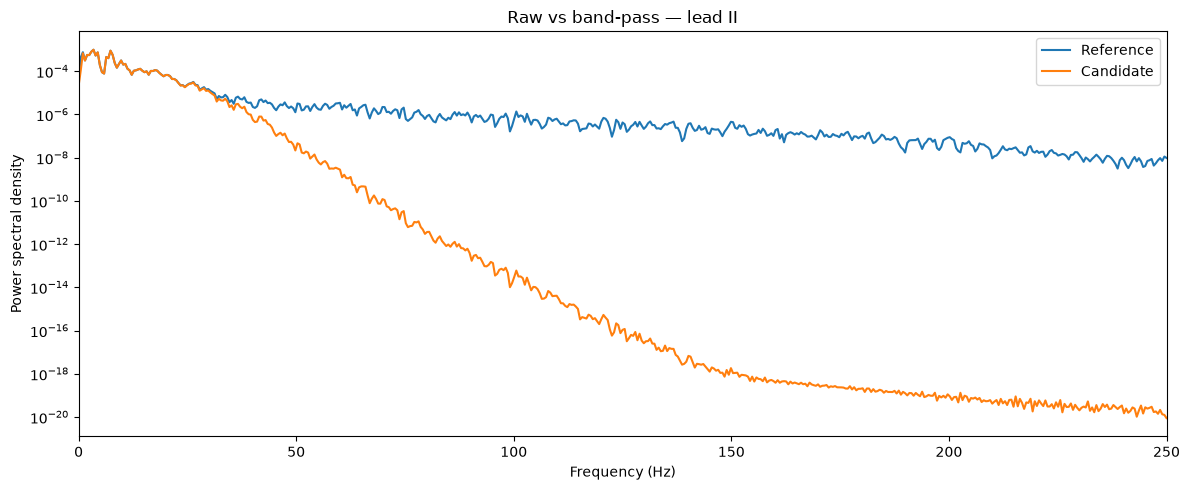

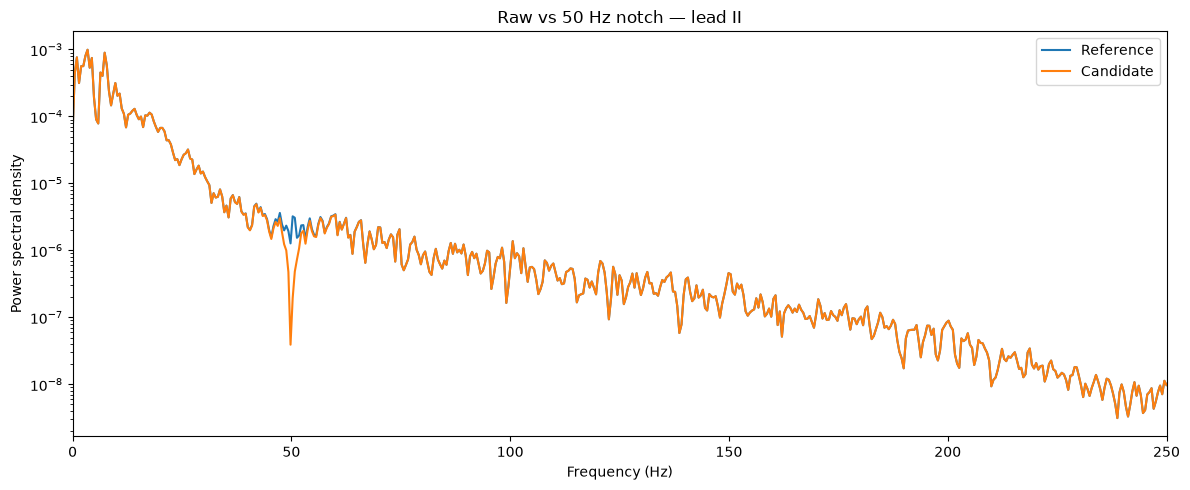

In [15]:
def plot_psd_comparison(
    reference: np.ndarray,
    candidate: np.ndarray,
    sampling_rate: float,
    lead_index: int,
    lead_name: str,
    title: str,
) -> None:
    """Plot Welch power spectral density for one lead before and after filtering."""
    nperseg = min(1024, len(reference), len(candidate))
    if nperseg < 2:
        raise ValueError("Signals must contain at least two samples for PSD.")

    f1, p1 = welch(
        reference[:, lead_index], fs=sampling_rate, nperseg=nperseg
    )
    f2, p2 = welch(
        candidate[:, lead_index], fs=sampling_rate, nperseg=nperseg
    )
    plt.figure(figsize=(12, 5))
    plt.semilogy(f1, p1, label="Reference")
    plt.semilogy(f2, p2, label="Candidate")
    plt.xlim(0, sampling_rate / 2)
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Power spectral density")
    plt.title(f"{title} — lead {lead_name}")
    plt.legend()
    plt.tight_layout()
    plt.show()


plot_psd_comparison(
    signal_raw, signal_bandpass, fs, lead_index,
    lead_names[lead_index], "Raw vs band-pass"
)
plot_psd_comparison(
    signal_raw, signal_notch, fs, lead_index,
    lead_names[lead_index], "Raw vs 50 Hz notch"
)

## Step 8: Quantify filter impact

In [16]:
def compare_signals(
    reference: np.ndarray,
    candidate: np.ndarray,
    names: list[str],
) -> pd.DataFrame:
    """Summarize per-lead amplitude and correlation changes after filtering."""
    if reference.shape != candidate.shape:
        raise ValueError("Reference and candidate signals must have equal shapes.")
    if reference.ndim != 2 or reference.shape[1] != len(names):
        raise ValueError("Lead names do not match the signal's channel dimension.")

    rows = []
    for i, name in enumerate(names):
        x = reference[:, i].astype(np.float64)
        y = candidate[:, i].astype(np.float64)
        corr = (
            float(np.corrcoef(x, y)[0, 1])
            if x.std() > 0 and y.std() > 0
            else np.nan
        )
        rows.append({
            "lead": name,
            "reference_rms_mV": float(np.sqrt(np.mean(x ** 2))),
            "candidate_rms_mV": float(np.sqrt(np.mean(y ** 2))),
            "difference_rms_mV": float(np.sqrt(np.mean((y - x) ** 2))),
            "correlation": corr,
        })
    return pd.DataFrame(rows).set_index("lead")


print("Raw vs band-pass")
display(compare_signals(signal_raw, signal_bandpass, lead_names).round(4))
print("Raw vs 50 Hz notch")
display(compare_signals(signal_raw, signal_notch, lead_names).round(4))

Raw vs band-pass


,reference_rms_mV,candidate_rms_mV,difference_rms_mV,correlation
lead,,,,
I,0.1116,0.0939,0.0603,0.8415
II,0.0860,0.0767,0.0383,0.8955
III,0.0600,0.0381,0.0448,0.6658
AVR,0.0949,0.0836,0.0451,0.8797
AVL,0.0785,0.0604,0.0495,0.7759
AVF,0.0487,0.0382,0.0287,0.8086
V1,0.1134,0.1111,0.0221,0.9808
V2,0.2158,0.2126,0.0298,0.9913
V3,0.1192,0.1155,0.0248,0.9782


Raw vs 50 Hz notch


,reference_rms_mV,candidate_rms_mV,difference_rms_mV,correlation
lead,,,,
I,0.1116,0.1113,0.0056,0.9987
II,0.0860,0.0859,0.0017,0.9998
III,0.0600,0.0597,0.0051,0.9964
AVR,0.0949,0.0948,0.0033,0.9994
AVL,0.0785,0.0782,0.0053,0.9977
AVF,0.0487,0.0485,0.0025,0.9986
V1,0.1134,0.1134,0.0010,1.0000
V2,0.2158,0.2157,0.0028,0.9999
V3,0.1192,0.1191,0.0016,0.9999


## Step 9: Inspect multiple training records

In [17]:
if "dataset_split" not in labels.columns:
    raise ValueError("dataset_split missing. Re-run Notebook 02.")

positive_ids = labels.index[
    labels["dataset_split"].eq("train") & labels["mi_label"].eq(1)
].to_numpy()
negative_ids = labels.index[
    labels["dataset_split"].eq("train") & labels["mi_label"].eq(0)
].to_numpy()

n_per_class = 3
if len(positive_ids) < n_per_class or len(negative_ids) < n_per_class:
    raise ValueError("Insufficient records for audit sample.")

audit_ids = [
    int(x) for x in np.concatenate([
        rng.choice(positive_ids, n_per_class, replace=False),
        rng.choice(negative_ids, n_per_class, replace=False),
    ])
]

display(labels.loc[audit_ids, ["patient_id", "dataset_split", "mi_label"]])

,patient_id,dataset_split,mi_label
ecg_id,,,
15720,12775.0,train,1
2964,3165.0,train,1
18209,6391.0,train,1
1811,3156.0,train,0
15068,17643.0,train,0
18678,15679.0,train,0


In [18]:
audit_rows = []
for ecg_id in audit_ids:
    ecg, record_fields = load_ecg_record(ecg_id, metadata, DATA_ROOT)
    audit_rows.append({
        "ecg_id": ecg_id,
        "mi_label": int(labels.loc[ecg_id, "mi_label"]),
        "fs_hz": float(record_fields["fs"]),
        "samples": ecg.shape[0],
        "leads": ecg.shape[1],
        "duration_s": ecg.shape[0] / float(record_fields["fs"]),
        "finite": bool(np.isfinite(ecg).all()),
        "min_mV": float(ecg.min()),
        "max_mV": float(ecg.max()),
        "std_mV": float(ecg.std()),
    })

audit_df = pd.DataFrame(audit_rows).set_index("ecg_id")
display(audit_df)

if not audit_df["finite"].all() or not audit_df["leads"].eq(12).all():
    raise ValueError("Audit sample contains invalid signal records.")

,mi_label,fs_hz,samples,leads,duration_s,finite,min_mV,max_mV,std_mV
ecg_id,,,,,,,,,
15720,1,500.0,5000,12,10.0,True,-1.421,1.109,0.143212
2964,1,500.0,5000,12,10.0,True,-2.133,2.942,0.371497
18209,1,500.0,5000,12,10.0,True,-1.349,2.351,0.213823
1811,0,500.0,5000,12,10.0,True,-1.651,2.403,0.247311
15068,0,500.0,5000,12,10.0,True,-2.183,1.903,0.179746
18678,0,500.0,5000,12,10.0,True,-2.053,2.345,0.252742


## Step 10: Plot the audit sample

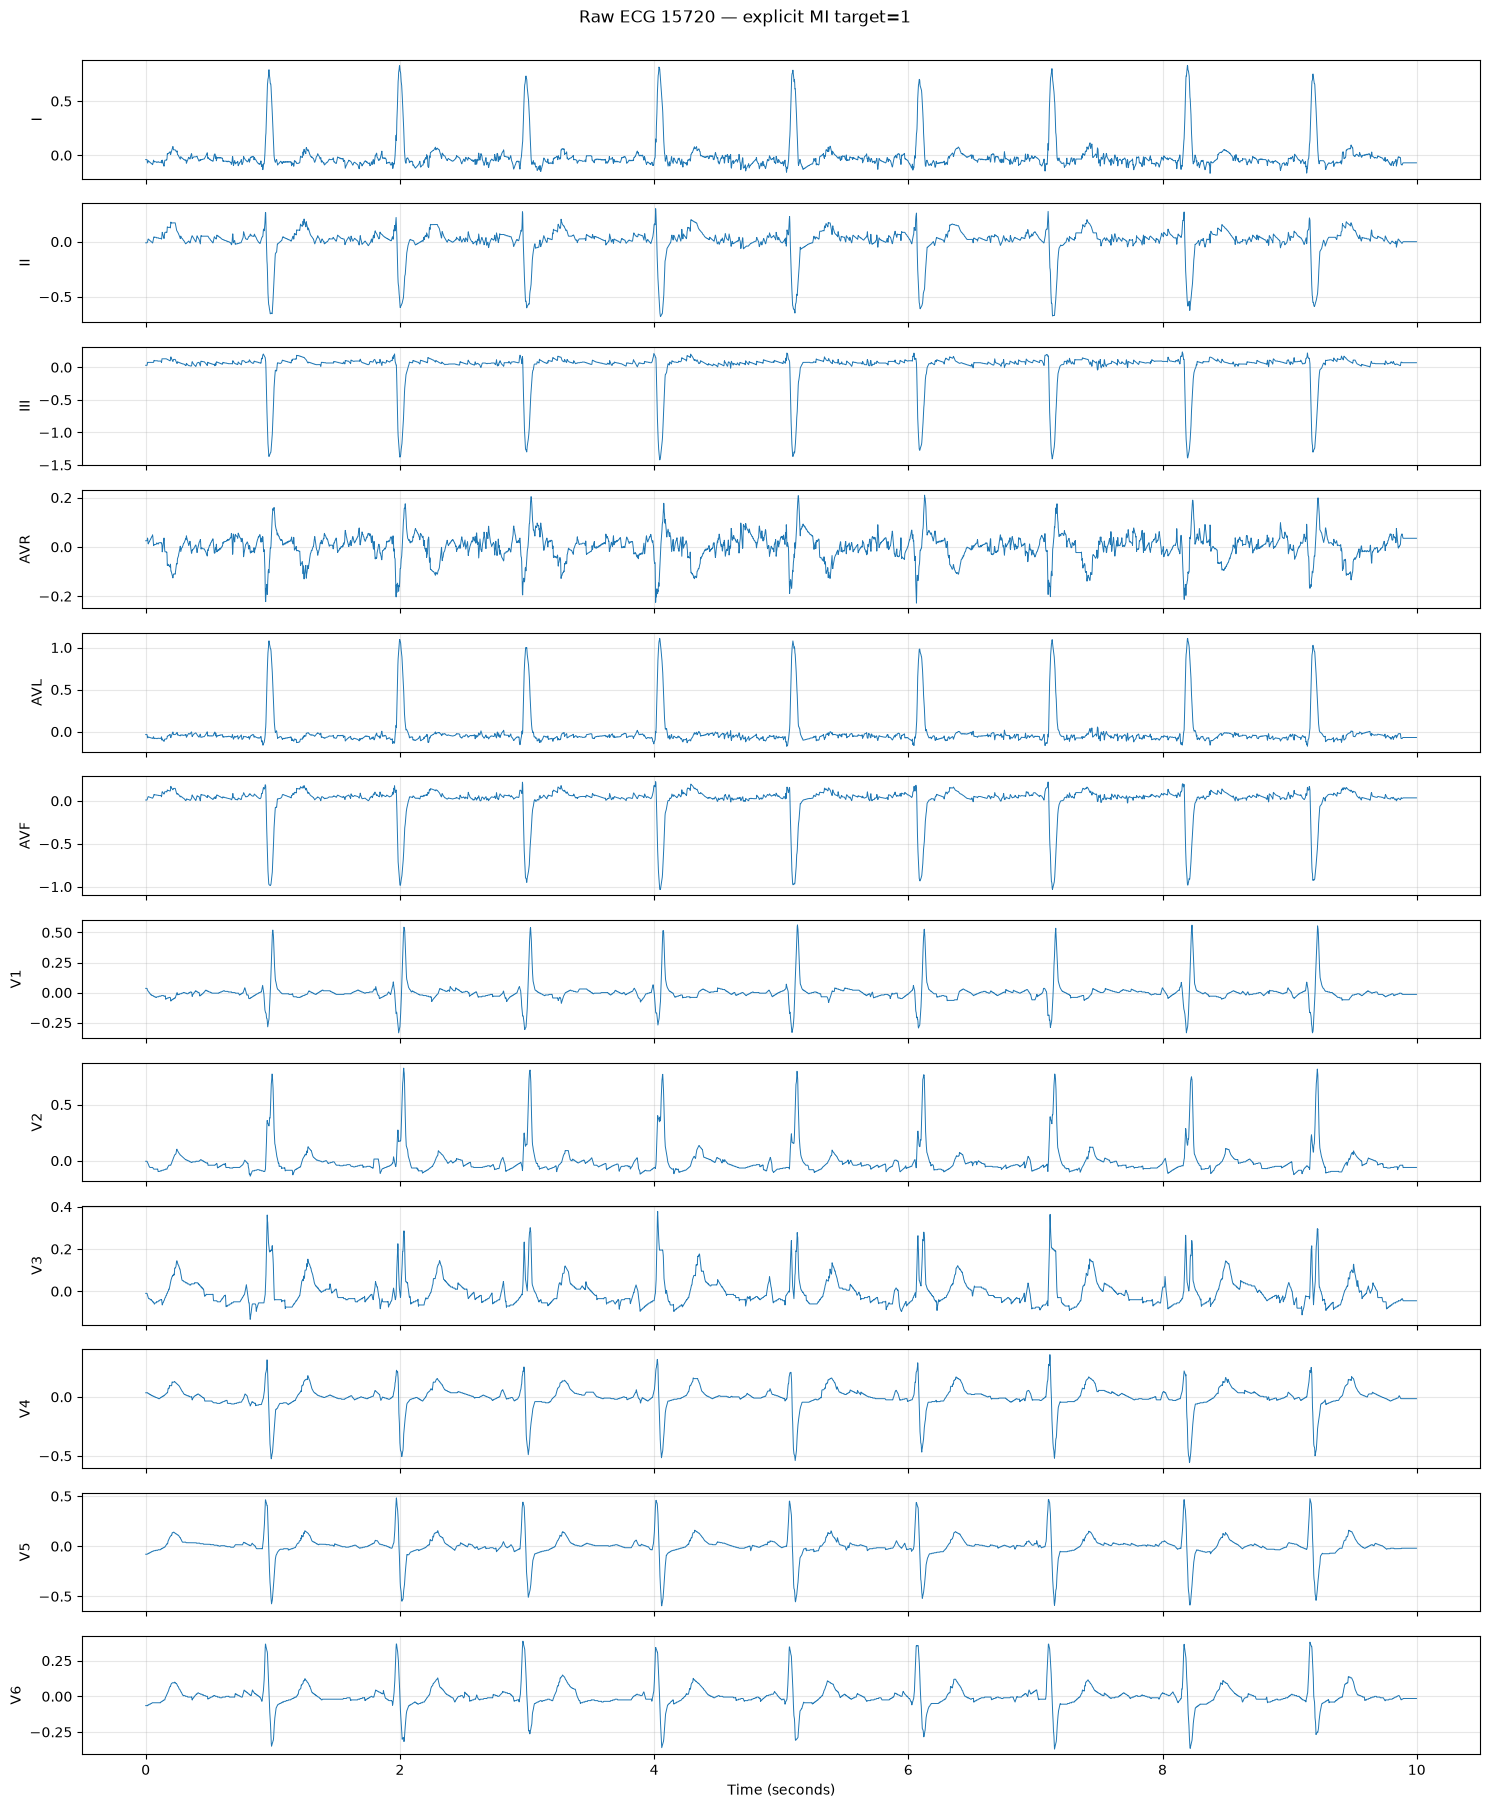

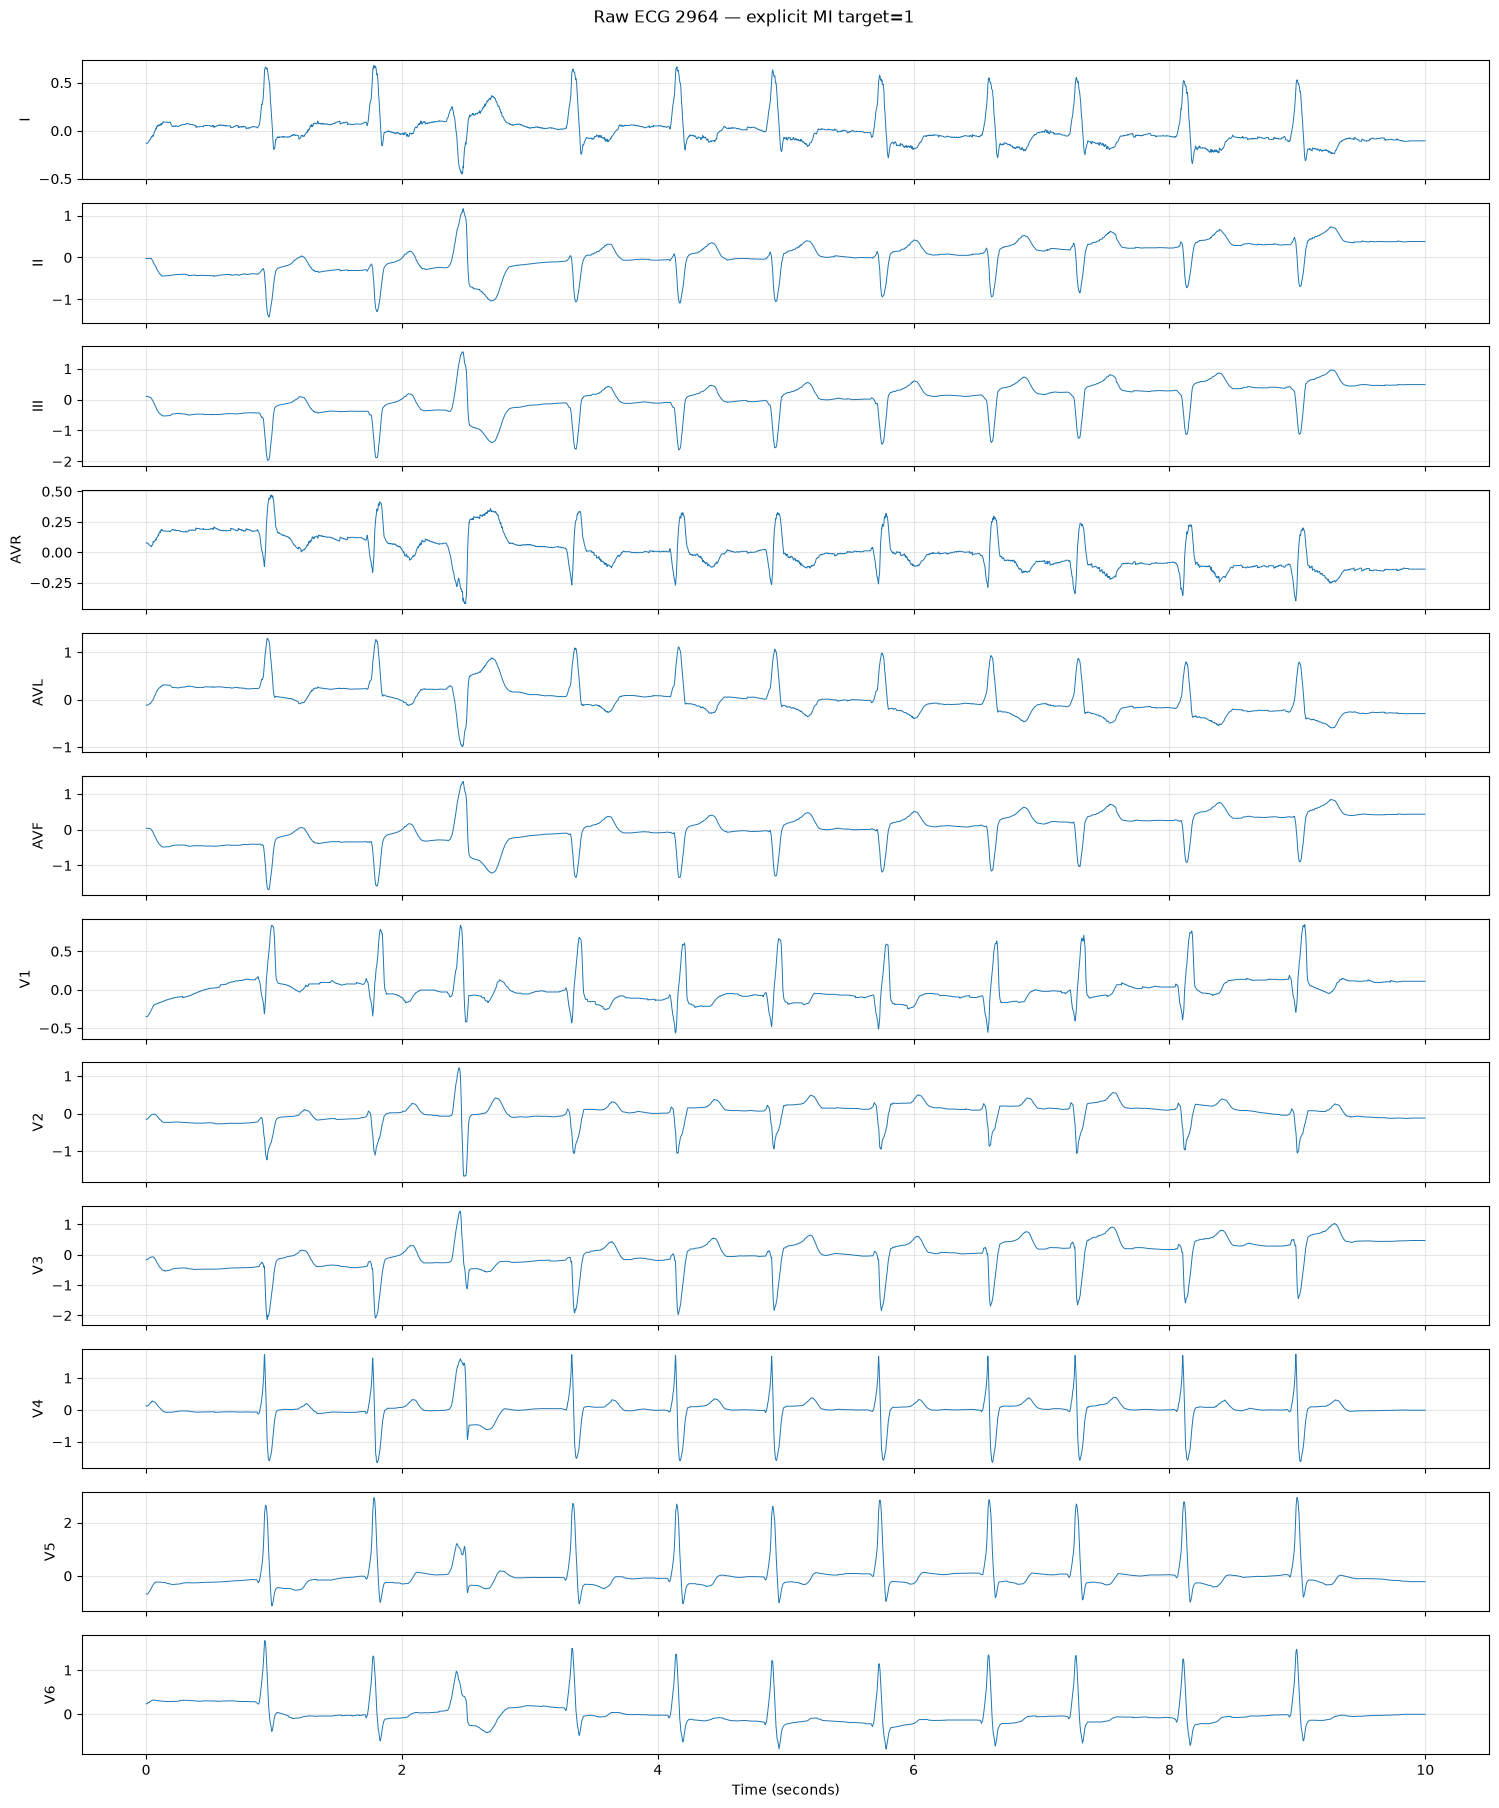

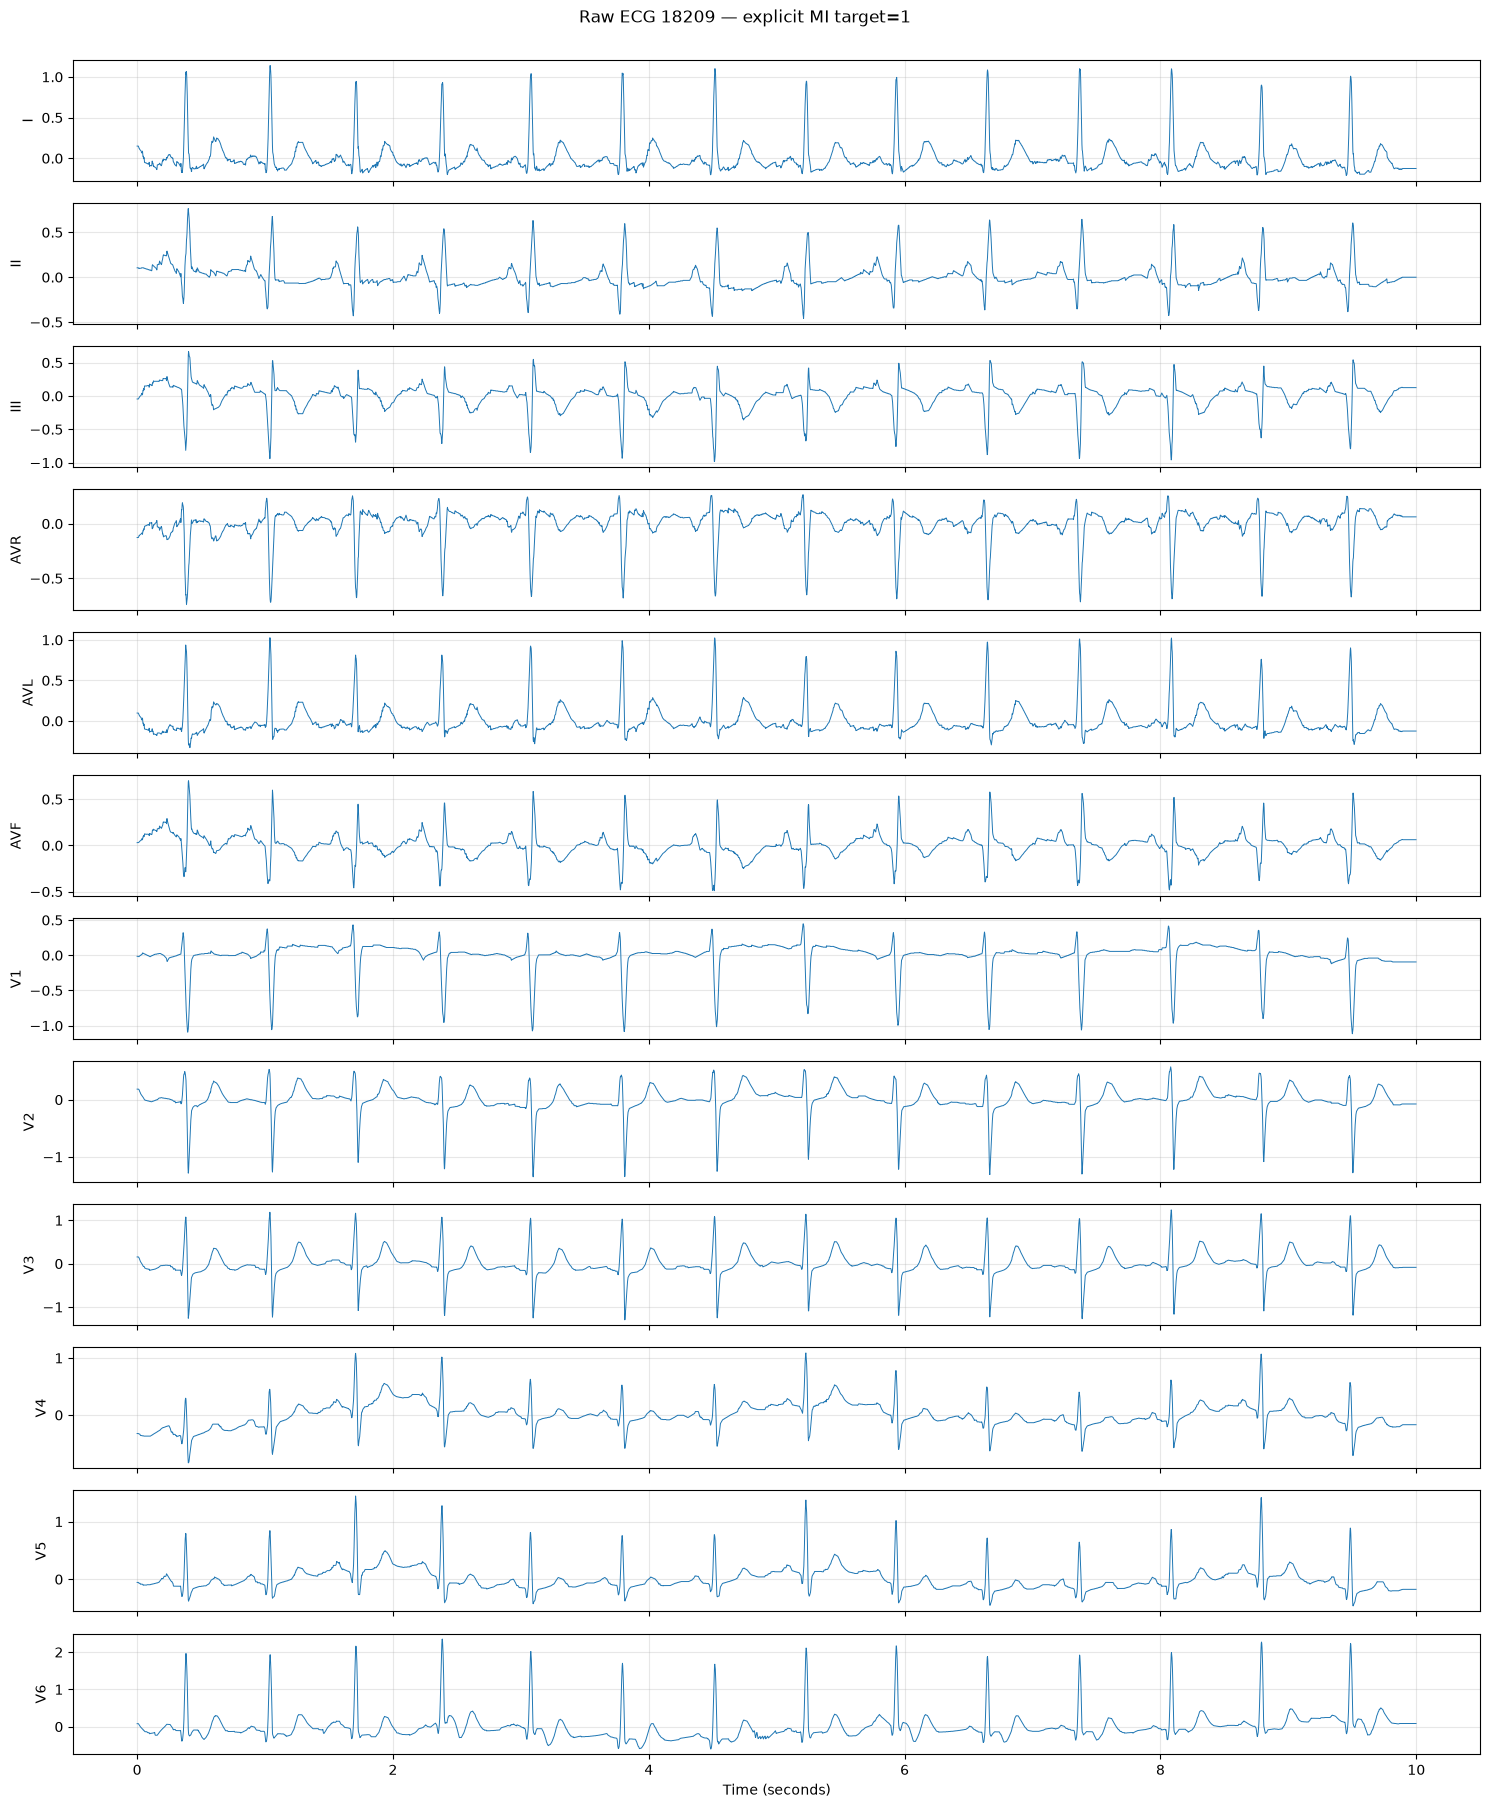

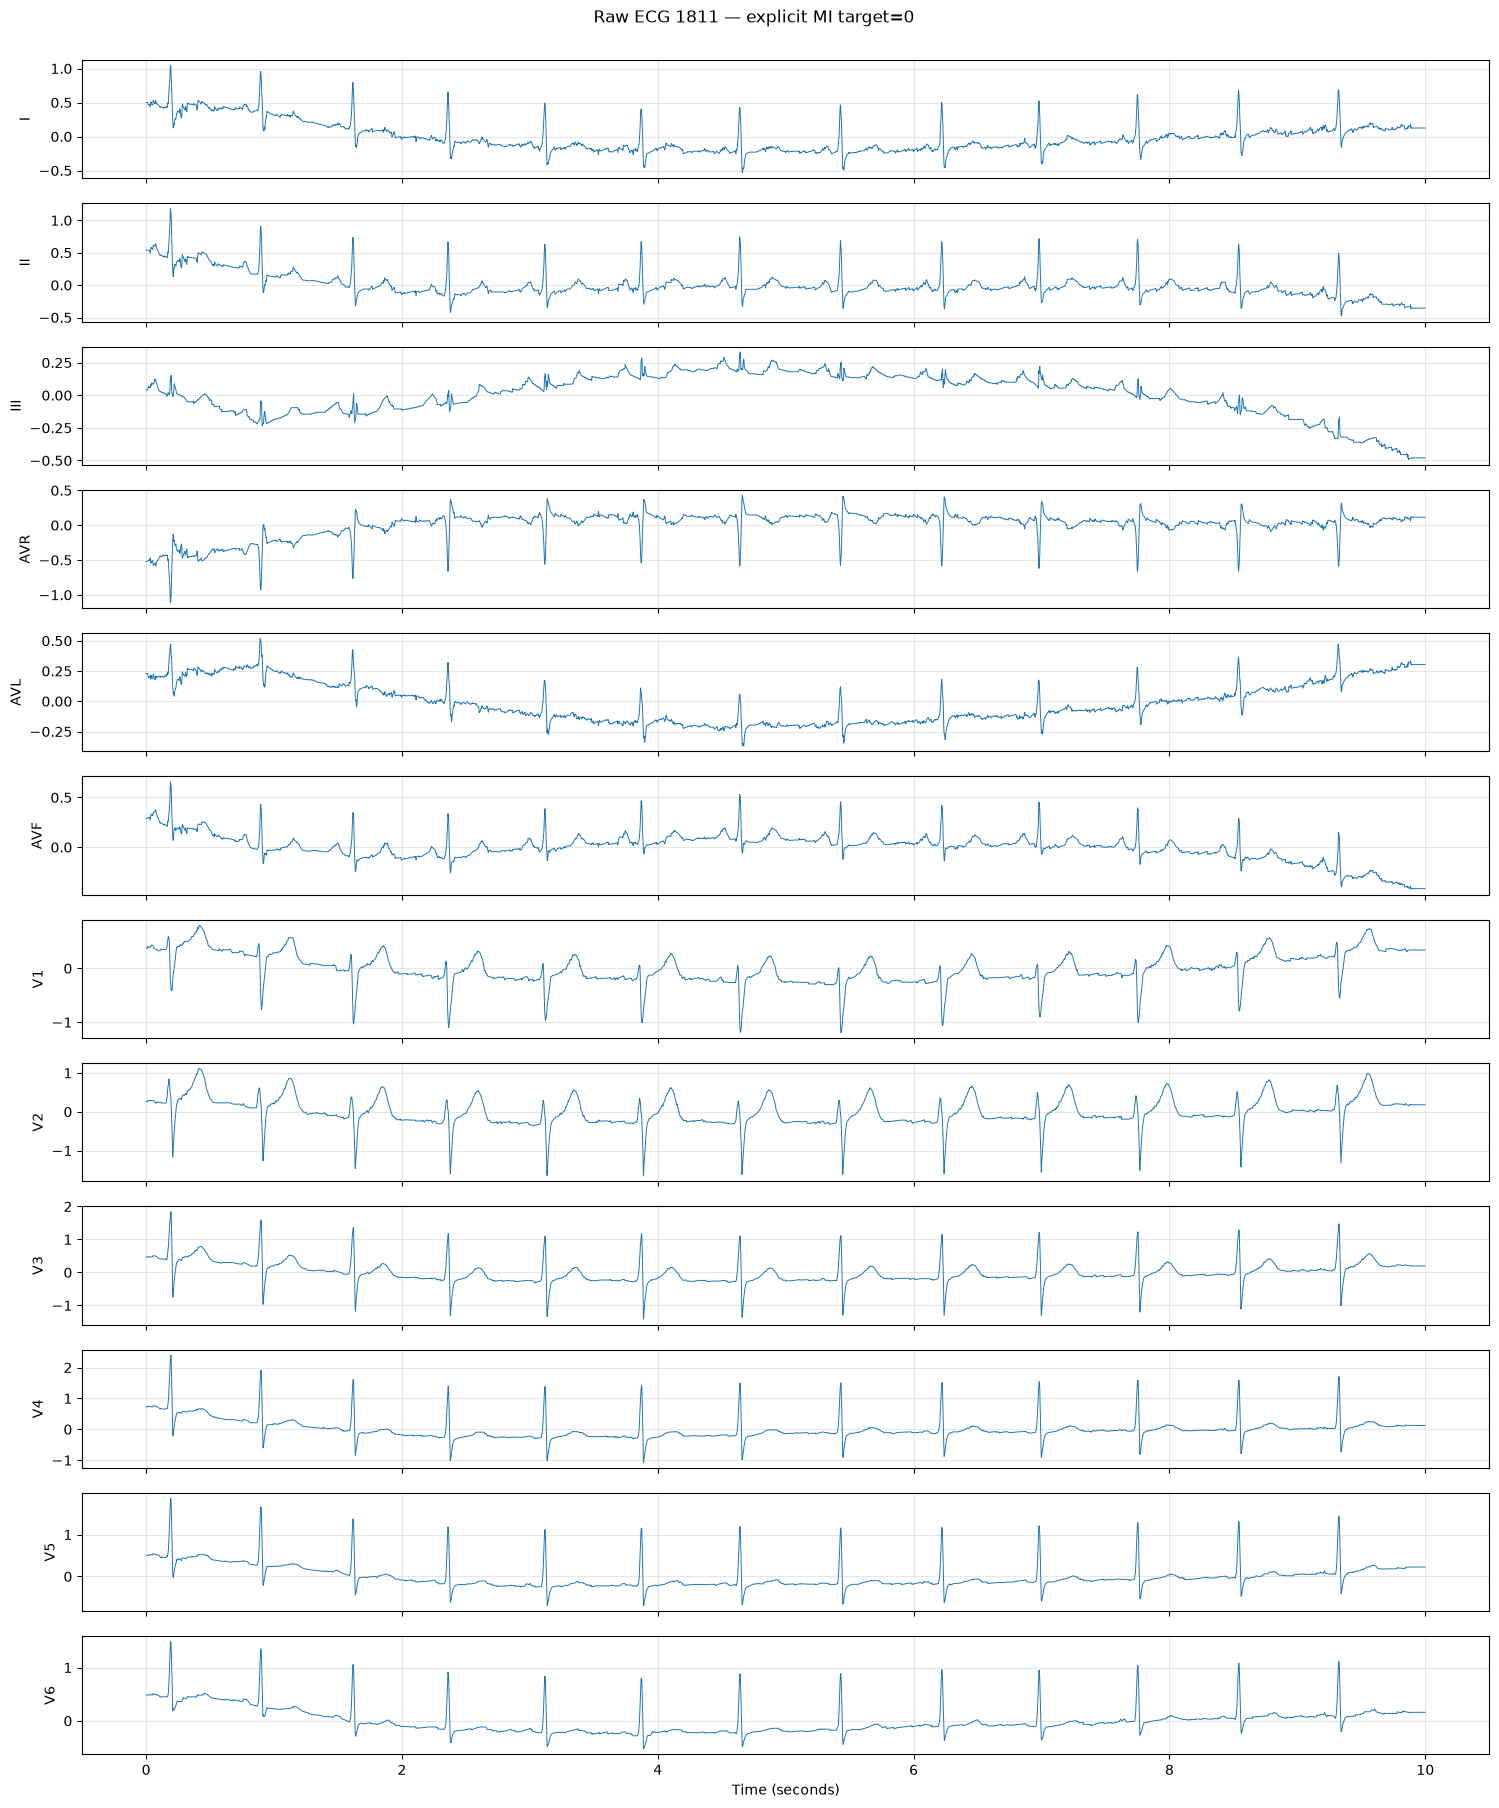

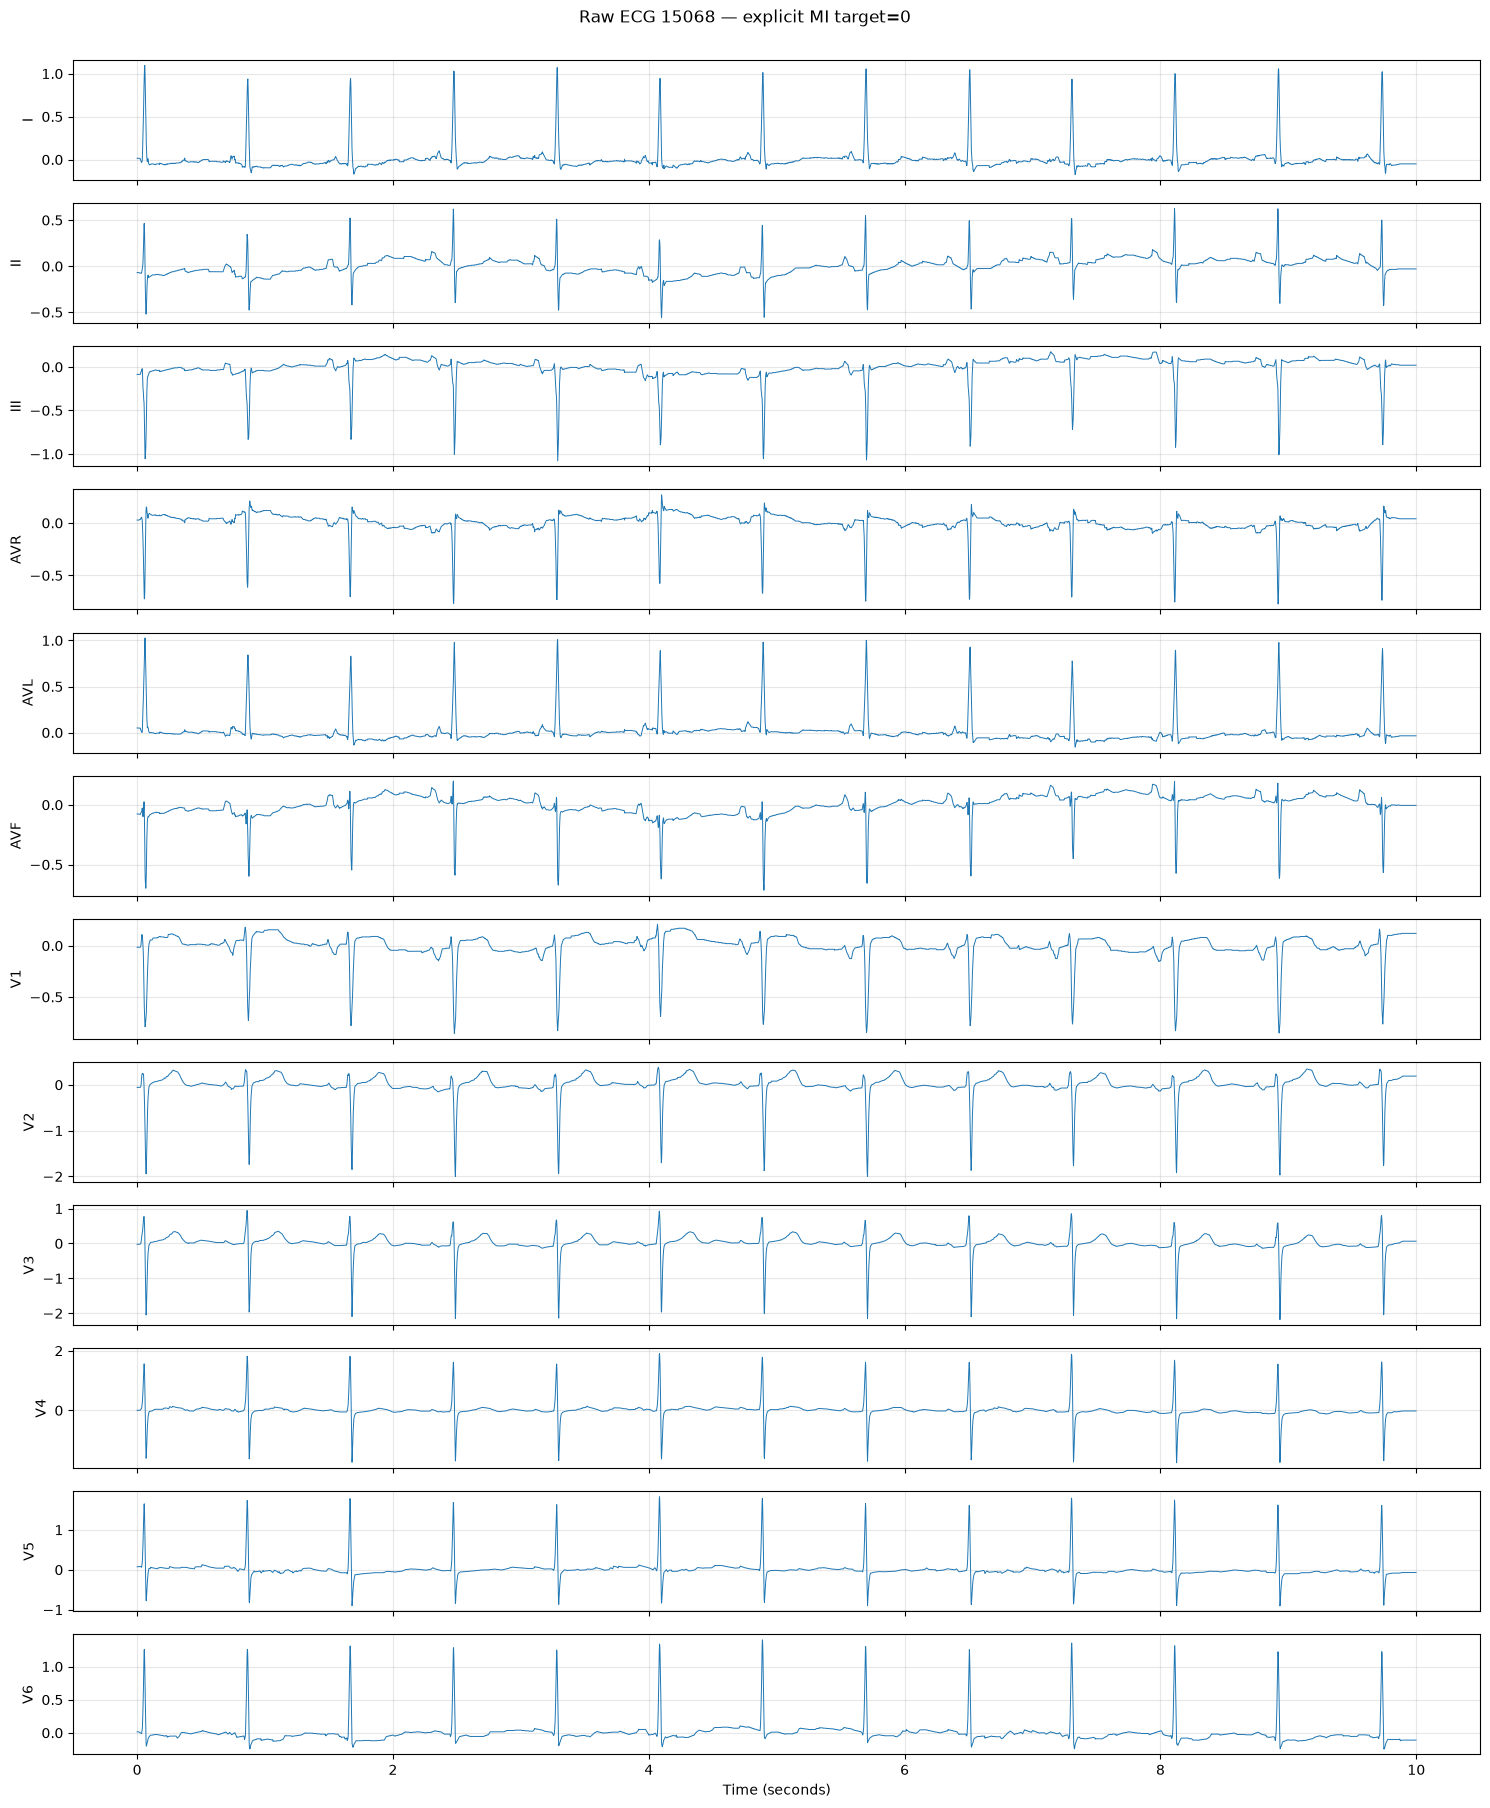

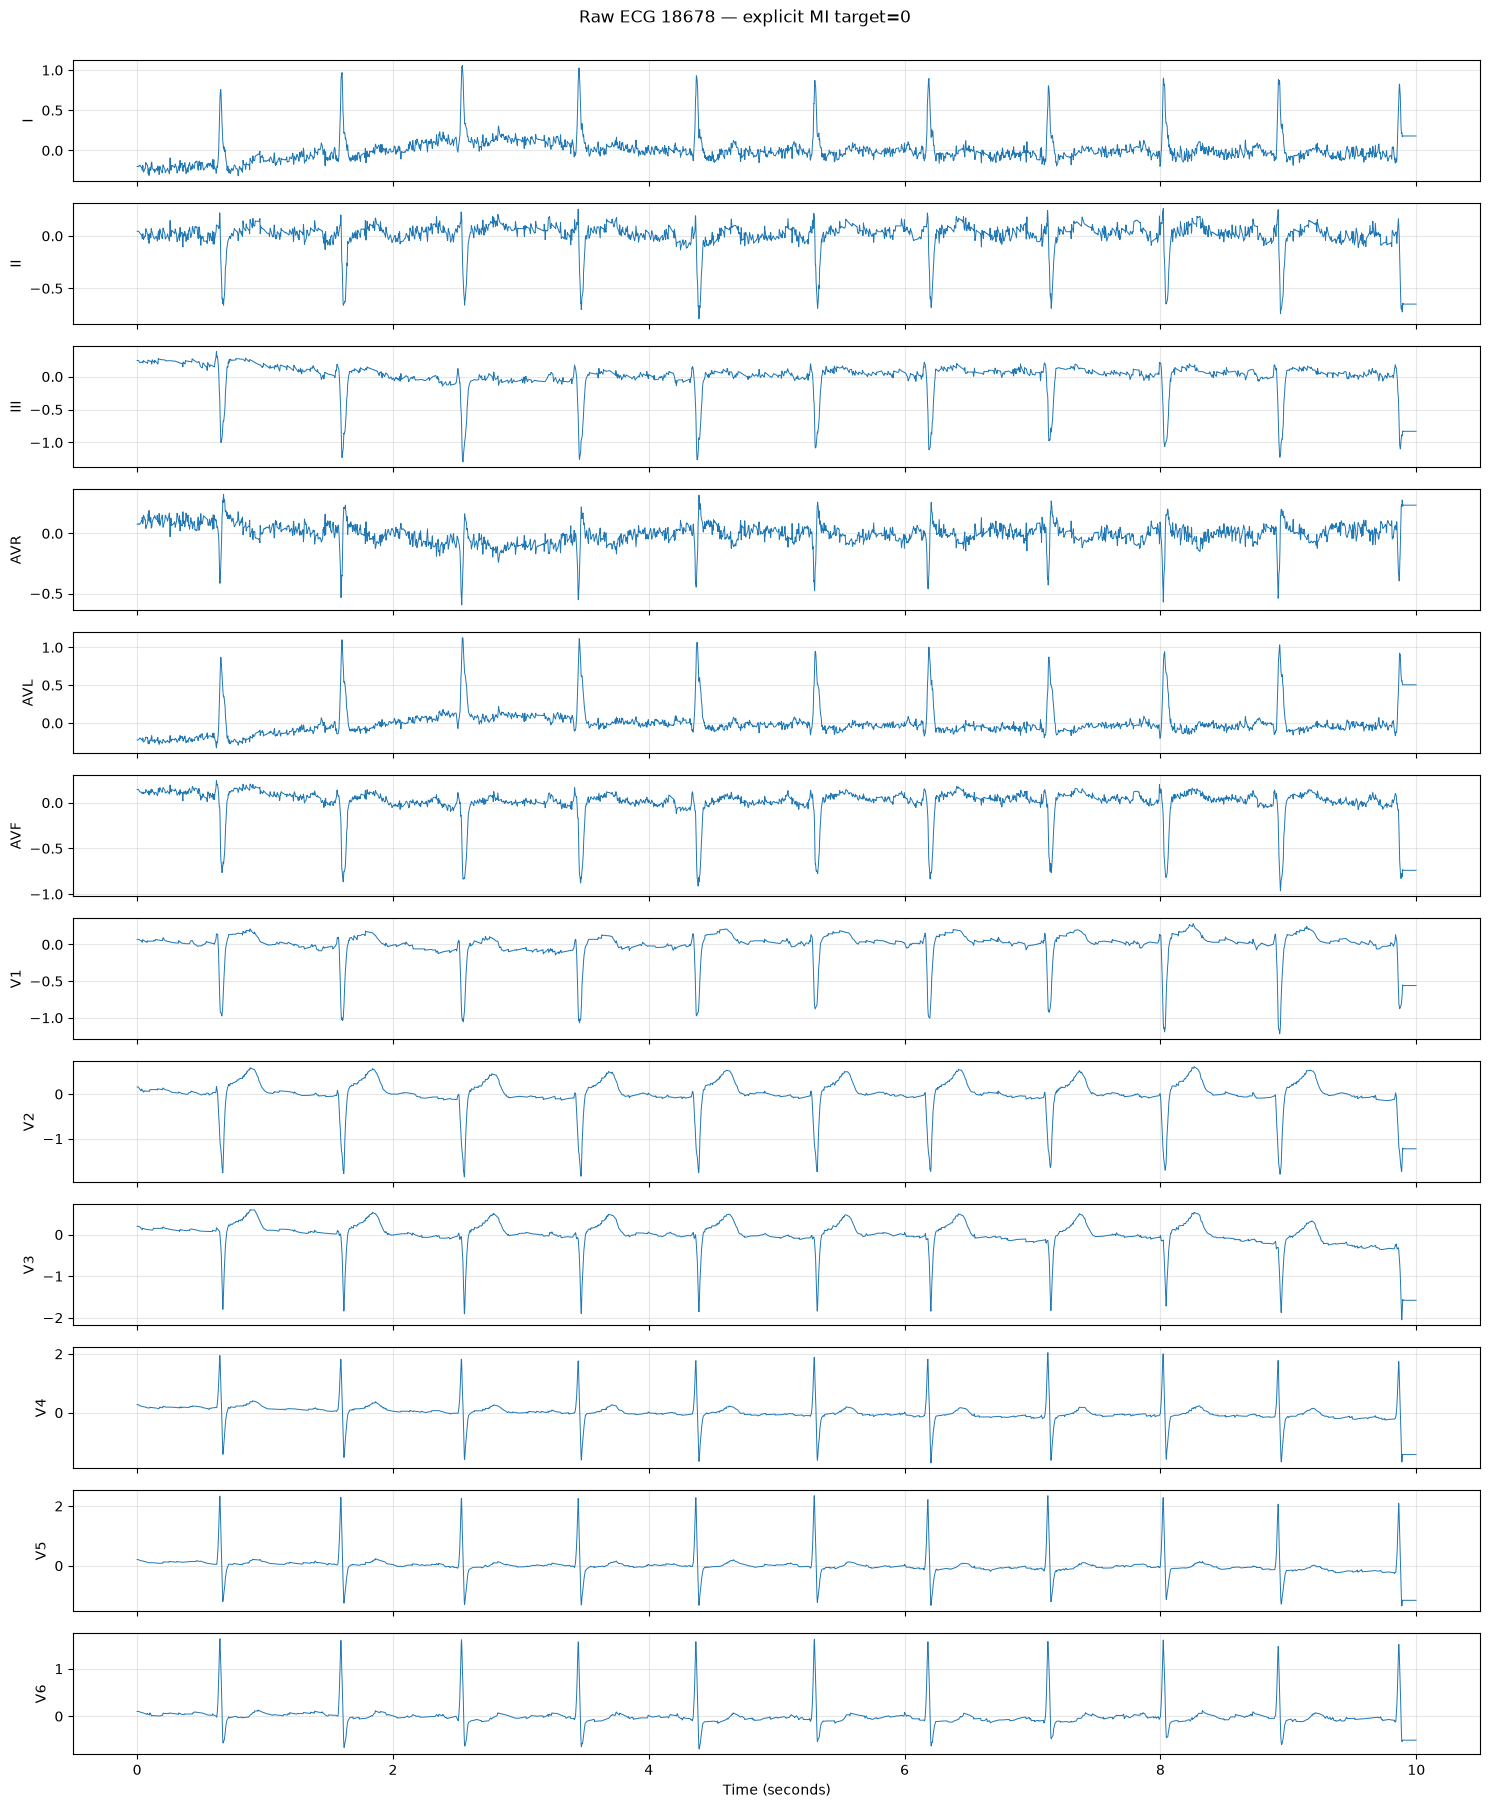

In [19]:
for ecg_id in audit_ids:
    ecg, record_fields = load_ecg_record(ecg_id, metadata, DATA_ROOT)
    plot_12_lead_ecg(
        ecg,
        float(record_fields["fs"]),
        list(record_fields["sig_name"]),
        f"Raw ECG {ecg_id} — explicit MI target={int(labels.loc[ecg_id, 'mi_label'])}",
    )

## Step 11: Provisional preprocessing configuration

In [20]:
PREPROCESSING_CONFIG = {
    "source_sampling_rate_hz": fs,
    "target_sampling_rate_hz": fs,
    "preserve_raw_signal": True,
    "bandpass": {
        "enabled": True,
        "type": "butterworth",
        "low_hz": BANDPASS_LOW_HZ,
        "high_hz": BANDPASS_HIGH_HZ,
        "order": FILTER_ORDER,
        "implementation": "scipy.signal.sosfiltfilt",
        "zero_phase": True,
    },
    "notch": {
        "enabled": False,
        "frequency_hz": NOTCH_FREQUENCY_HZ,
        "quality_factor": NOTCH_QUALITY_FACTOR,
        "implementation": "scipy.signal.filtfilt",
        "reason_disabled": (
            "The 40 Hz low-pass already attenuates 50 Hz mains interference; "
            "do not apply a redundant 50 Hz notch after this band-pass."
        ),
    },
    "normalization": {
        "enabled": False,
        "method": None,
        "fit_on_training_data_only": True,
    },
    "notes": (
        "Provisional configuration. Compare filter settings and inspect "
        "morphology before full processing. A 0.5 Hz high-pass can alter "
        "ST-segment morphology; include a lower-cutoff sensitivity analysis "
        "when evaluating MI-related morphology."
    ),
}

print(json.dumps(PREPROCESSING_CONFIG, indent=4))

{
    "source_sampling_rate_hz": 500.0,
    "target_sampling_rate_hz": 500.0,
    "preserve_raw_signal": true,
    "bandpass": {
        "enabled": true,
        "type": "butterworth",
        "low_hz": 0.5,
        "high_hz": 40.0,
        "order": 4,
        "implementation": "scipy.signal.sosfiltfilt",
        "zero_phase": true
    },
    "notch": {
        "enabled": false,
        "frequency_hz": 50.0,
        "quality_factor": 30.0,
        "implementation": "scipy.signal.filtfilt",
        "reason_disabled": "The 40 Hz low-pass already attenuates 50 Hz mains interference; do not apply a redundant 50 Hz notch after this band-pass."
    },
    "normalization": {
        "enabled": false,
        "method": null,
        "fit_on_training_data_only": true
    },
    "notes": "Provisional configuration. Compare filter settings and inspect morphology before full processing. A 0.5 Hz high-pass can alter ST-segment morphology; include a lower-cutoff sensitivity analysis when evaluating 

## Step 12: Apply configuration to the example record

In [21]:
def preprocess_ecg(
    signal: np.ndarray,
    sampling_rate: float,
    config: dict[str, Any],
) -> np.ndarray:
    """Apply configured offline filters; normalization is not performed."""
    signal = np.asarray(signal, dtype=np.float32)
    if signal.ndim != 2 or signal.shape[1] != 12:
        raise ValueError("Expected ECG input with shape (samples, 12).")
    if not np.isfinite(signal).all():
        raise ValueError("Input ECG contains NaN or infinity.")

    processed = signal.copy()

    bp = config["bandpass"]
    if bp["enabled"]:
        processed = apply_bandpass(
            processed,
            sampling_rate,
            low_hz=float(bp["low_hz"]),
            high_hz=float(bp["high_hz"]),
            order=int(bp["order"]),
        )

    notch = config["notch"]
    if notch["enabled"]:
        processed = apply_notch(
            processed,
            sampling_rate,
            frequency_hz=float(notch["frequency_hz"]),
            quality_factor=float(notch["quality_factor"]),
        )

    if processed.shape != signal.shape:
        raise RuntimeError("Filtering changed the signal shape.")
    if not np.isfinite(processed).all():
        raise ValueError("Filtered signal contains NaN or infinity.")

    return processed.astype(np.float32)


signal_processed = preprocess_ecg(signal_raw, fs, PREPROCESSING_CONFIG)
print("Input:", signal_raw.shape, signal_raw.dtype)
print("Output:", signal_processed.shape, signal_processed.dtype)
print("Output min/max mV:", float(signal_processed.min()), float(signal_processed.max()))

Input: (5000, 12) float32
Output: (5000, 12) float32
Output min/max mV: -1.392561674118042 0.6204022765159607


## Step 13: Save configuration and example output

In [22]:
config_path = OUTPUT_DIR / "preprocessing_config.json"
with config_path.open("w", encoding="utf-8") as file:
    json.dump(PREPROCESSING_CONFIG, file, indent=4)

example_path = OUTPUT_DIR / f"ecg_{example_ecg_id}_preprocessing_example.npz"
np.savez_compressed(
    example_path,
    raw_signal=signal_raw.astype(np.float32),
    processed_signal=signal_processed.astype(np.float32),
    sampling_rate=np.asarray(fs, dtype=np.float32),
    lead_names=np.asarray(lead_names),
    ecg_id=np.asarray(example_ecg_id),
)

report = {
    "example_ecg_id": example_ecg_id,
    "signal_shape": list(signal_raw.shape),
    "sampling_rate_hz": fs,
    "duration_seconds": signal_raw.shape[0] / fs,
    "lead_names": lead_names,
    "units": fields.get("units", []),
    "audit_ecg_ids": audit_ids,
    "audit_records": audit_df.reset_index().to_dict(orient="records"),
    "preprocessing_config": PREPROCESSING_CONFIG,
}
report_path = OUTPUT_DIR / "preprocessing_audit_report.json"
with report_path.open("w", encoding="utf-8") as file:
    json.dump(report, file, indent=4)

print("Saved configuration:", config_path.resolve())
print("Saved example:", example_path.resolve())
print("Saved report:", report_path.resolve())

Saved configuration: C:\Users\sintu\Desktop\Myocardial Infarction\results\preprocessing\preprocessing_config.json
Saved example: C:\Users\sintu\Desktop\Myocardial Infarction\results\preprocessing\ecg_1_preprocessing_example.npz
Saved report: C:\Users\sintu\Desktop\Myocardial Infarction\results\preprocessing\preprocessing_audit_report.json
